In [1]:
import sys
from pathlib import Path

# Detecta dinamicamente a raiz do projeto (um nível acima de notebooks/)
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: "%.4f" % x)

# Caminho absoluto/relativo robusto para os dados brutos
caminho_raw = ROOT_DIR / "data" / "raw" / "dados_sensores_vulcantech.csv"
print(f"Buscando arquivo em: {caminho_raw.resolve()}")

df = pd.read_csv(caminho_raw)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values(by=["id_celula", "timestamp"]).reset_index(drop=True)

print(f"Dataset carregado com sucesso: {df.shape[0]} linhas e {df.shape[1]} colunas.")
df.head()

Buscando arquivo em: C:\Users\henrique_schorck\Documents\GitHub\Projeto-Integrador-Vulcan\data\raw\dados_sensores_vulcantech.csv
Dataset carregado com sucesso: 10000 linhas e 11 colunas.


,timestamp,id_celula,liga_metalica,temperatura_fuso_c,vibracao_triaxial_rms_mms,torque_fuso_nm,vazao_refrigerante_lmin,corrente_estator_amp,pressao_hidraulica_bar,nivel_ruido_db,tipo_falha
0,2026-10-01 00:15:00,CEL-201,Aco_Carbono_316L,58.1800,1.9000,101.8900,29.3100,27.7700,162.2800,52.9300,0
1,2026-10-01 00:35:00,CEL-201,Aco_Carbono_316L,45.7600,1.9400,102.7100,32.5300,27.1800,169.2100,53.8000,0
2,2026-10-01 00:40:00,CEL-201,Aco_Carbono_316L,53.6500,1.4200,95.0600,25.6700,31.1400,152.8300,53.5400,0
3,2026-10-01 01:00:00,CEL-201,Aluminio_7075,70.9200,2.5400,103.1300,5.1400,31.0200,166.9300,45.0800,2
4,2026-10-01 01:05:00,CEL-201,Aluminio_7075,80.9800,1.4000,113.4600,4.6200,20.1900,162.5800,48.4600,2


In [2]:
sensor_cols = [
    "temperatura_fuso_c",
    "vibracao_triaxial_rms_mms",
    "torque_fuso_nm",
    "vazao_refrigerante_lmin",
    "corrente_estator_amp",
    "pressao_hidraulica_bar",
    "nivel_ruido_db"
]

taxa_nans = (
    df.groupby(["id_celula", "liga_metalica"])[sensor_cols]
    .apply(lambda g: (g.isna().mean() * 100))
    .round(2)
)

print("--- Taxa de Ausência de Dados (NaNs em %) por Célula e Liga ---")
display(taxa_nans)

--- Taxa de Ausência de Dados (NaNs em %) por Célula e Liga ---


temperatura_fuso_c  vibracao_triaxial_rms_mms  \
id_celula liga_metalica                                                         
CEL-201   Aco_Carbono_316L                  2.2800                     2.2000   
          Aluminio_7075                     3.3100                     1.7800   
          Liga_Titanio_Ti6Al4V              2.0500                     2.4600   
CEL-202   Aco_Carbono_316L                  3.6600                     2.4900   
          Aluminio_7075                     1.9100                     2.2900   
          Liga_Titanio_Ti6Al4V              1.9600                     2.5400   
CEL-203   Aco_Carbono_316L                  2.6700                     3.2400   
          Aluminio_7075                     1.5500                     2.2600   
          Liga_Titanio_Ti6Al4V              2.6200                     2.2100   
CEL-204   Aco_Carbono_316L                  2.5300                     2.6100   
          Aluminio_7075                     1.9800                     3.4400   
          Liga_Titanio_Ti6Al4V              2.2300                     1.8200   

                                torque_fuso_nm  vazao_refrigerante_lmin  \
id_celula liga_metalica                                                   
CEL-201   Aco_Carbono_316L              0.0000                   2.0300   
          Aluminio_7075                 0.0000                   1.5300   
          Liga_Titanio_Ti6Al4V          0.0000                   2.0500   
CEL-202   Aco_Carbono_316L              0.0000                   2.5700   
          Aluminio_7075                 0.0000                   1.6500   
          Liga_Titanio_Ti6Al4V          0.0000                   1.9600   
CEL-203   Aco_Carbono_316L              0.0000                   1.1300   
          Aluminio_7075                 0.0000                   1.6900   
          Liga_Titanio_Ti6Al4V          0.0000                   1.0100   
CEL-204   Aco_Carbono_316L              0.0000                   3.4300   
          Aluminio_7075                 0.0000                   2.2500   
          Liga_Titanio_Ti6Al4V          0.0000                   1.4200   

                                corrente_estator_amp  pressao_hidraulica_bar  \
id_celula liga_metalica                                                        
CEL-201   Aco_Carbono_316L                    0.0000                  0.0000   
          Aluminio_7075                       0.0000                  0.0000   
          Liga_Titanio_Ti6Al4V                0.0000                  0.0000   
CEL-202   Aco_Carbono_316L                    0.0000                  0.0000   
          Aluminio_7075                       0.0000                  0.0000   
          Liga_Titanio_Ti6Al4V                0.0000                  0.0000   
CEL-203   Aco_Carbono_316L                    0.0000                  0.0000   
          Aluminio_7075                       0.0000                  0.0000   
          Liga_Titanio_Ti6Al4V                0.0000                  0.0000   
CEL-204   Aco_Carbono_316L                    0.0000                  0.0000   
          Aluminio_7075                       0.0000                  0.0000   
          Liga_Titanio_Ti6Al4V                0.0000                  0.0000   

                                nivel_ruido_db  
id_celula liga_metalica                         
CEL-201   Aco_Carbono_316L              0.0000  
          Aluminio_7075                 0.0000  
          Liga_Titanio_Ti6Al4V          0.0000  
CEL-202   Aco_Carbono_316L              0.0000  
          Aluminio_7075                 0.0000  
          Liga_Titanio_Ti6Al4V          0.0000  
CEL-203   Aco_Carbono_316L              0.0000  
          Aluminio_7075                 0.0000  
          Liga_Titanio_Ti6Al4V          0.0000  
CEL-204   Aco_Carbono_316L              0.0000  
          Aluminio_7075                 0.0000  
          Liga_Titanio_Ti6Al4V          0.0000

In [3]:
df_sanitizado = df.copy()

# Limites físicos estritos de viabilidade (sensores desconectados / estouro de escala)
df_sanitizado.loc[df_sanitizado["temperatura_fuso_c"] >= 900.0, "temperatura_fuso_c"] = np.nan
df_sanitizado.loc[df_sanitizado["vibracao_triaxial_rms_mms"] < 0.0, "vibracao_triaxial_rms_mms"] = np.nan
df_sanitizado.loc[df_sanitizado["pressao_hidraulica_bar"] < 0.0, "pressao_hidraulica_bar"] = np.nan
df_sanitizado.loc[df_sanitizado["vazao_refrigerante_lmin"] < 0.0, "vazao_refrigerante_lmin"] = np.nan

# Diagnóstico pós-conversão de ruídos em NaNs
nans_pos_ruido = df_sanitizado[sensor_cols].isna().sum()
print("Volume total de lacunas a serem interpoladas (originais + ruídos saneados):")
print(nans_pos_ruido)

Volume total de lacunas a serem interpoladas (originais + ruídos saneados):
temperatura_fuso_c           300
vibracao_triaxial_rms_mms    299
torque_fuso_nm                 0
vazao_refrigerante_lmin      201
corrente_estator_amp           0
pressao_hidraulica_bar        50
nivel_ruido_db                 0
dtype: int64


In [4]:
# Ordenar estritamente por célula e timestamp 
df_sanitizado = df_sanitizado.sort_values(by=["id_celula", "timestamp"]).reset_index(drop=True)

# Interpolação temporal agrupada por id_celula
df_interpolado = df_sanitizado.copy()

df_interpolado[sensor_cols] = (
    df_sanitizado.groupby("id_celula")[sensor_cols]
    .transform(lambda grupo: grupo.interpolate(method="linear").bfill().ffill())
)

print(f"NaNs remanescentes após interpolação condicional: {df_interpolado[sensor_cols].isna().sum().sum()}")

NaNs remanescentes após interpolação condicional: 0


In [5]:
df_features = df_interpolado.copy()

# 1. Feature Derivada: Índice de Esforço Mecânico (IEM)
df_features["indice_esforco_mecanico"] = (
    df_features["torque_fuso_nm"] * df_features["vibracao_triaxial_rms_mms"]
) / (df_features["vazao_refrigerante_lmin"] + 1.0)

# 2. Sensores críticos para monitoramento de degradação temporal
sensores_dinamicos = ["temperatura_fuso_c", "vibracao_triaxial_rms_mms", "torque_fuso_nm", "indice_esforco_mecanico"]

# 3. Rolling Features por célula (amostragem a cada 5 min: 6 passos = 30min; 24 passos = 2h)
janelas = {"30m": 6, "2h": 24}

for rotulo, w in janelas.items():
    for col in sensores_dinamicos:
        df_features[f"{col}_roll_mean_{rotulo}"] = (
            df_features.groupby("id_celula")[col]
            .transform(lambda x: x.rolling(window=w, min_periods=1).mean())
        )
        df_features[f"{col}_roll_std_{rotulo}"] = (
            df_features.groupby("id_celula")[col]
            .transform(lambda x: x.rolling(window=w, min_periods=1).std().fillna(0.0))
        )

print("Novas colunas geradas:")
print([col for col in df_features.columns if "roll" in col or "esforco" in col])

Novas colunas geradas:
['indice_esforco_mecanico', 'temperatura_fuso_c_roll_mean_30m', 'temperatura_fuso_c_roll_std_30m', 'vibracao_triaxial_rms_mms_roll_mean_30m', 'vibracao_triaxial_rms_mms_roll_std_30m', 'torque_fuso_nm_roll_mean_30m', 'torque_fuso_nm_roll_std_30m', 'indice_esforco_mecanico_roll_mean_30m', 'indice_esforco_mecanico_roll_std_30m', 'temperatura_fuso_c_roll_mean_2h', 'temperatura_fuso_c_roll_std_2h', 'vibracao_triaxial_rms_mms_roll_mean_2h', 'vibracao_triaxial_rms_mms_roll_std_2h', 'torque_fuso_nm_roll_mean_2h', 'torque_fuso_nm_roll_std_2h', 'indice_esforco_mecanico_roll_mean_2h', 'indice_esforco_mecanico_roll_std_2h']


In [6]:
# Normalização condicional: Razão em relação à média histórica da respectiva liga metálica
for col in sensor_cols + ["indice_esforco_mecanico"]:
    media_liga = df_features.groupby("liga_metalica")[col].transform("mean")
    df_features[f"{col}_ratio_liga"] = df_features[col] / media_liga

# Validação do baseline: média das variáveis normalizadas por liga deve ser ~1.0
validacao_norm = df_features.groupby("liga_metalica")[[f"{c}_ratio_liga" for c in ["torque_fuso_nm", "temperatura_fuso_c"]]].mean()
print("--- Validação da Normalização por Liga (Médias devem ser iguais a 1.0) ---")
display(validacao_norm)

--- Validação da Normalização por Liga (Médias devem ser iguais a 1.0) ---


,torque_fuso_nm_ratio_liga,temperatura_fuso_c_ratio_liga
liga_metalica,,
Aco_Carbono_316L,1.0000,1.0000
Aluminio_7075,1.0000,1.0000
Liga_Titanio_Ti6Al4V,1.0000,1.0000


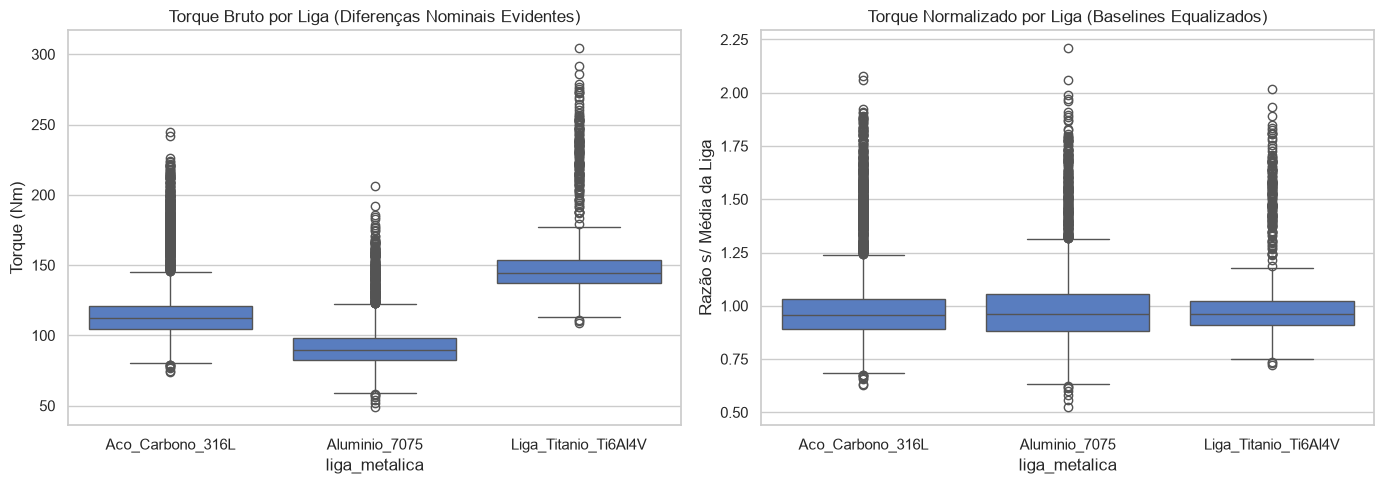

Base tratada salva com sucesso em: C:\Users\henrique_schorck\Documents\GitHub\Projeto-Integrador-Vulcan\data\processed\dados_sensores_tratados.csv


In [7]:
# Visualização do impacto da normalização na eliminação de viés de material
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_features, x="liga_metalica", y="torque_fuso_nm", ax=axes[0])
axes[0].set_title("Torque Bruto por Liga (Diferenças Nominais Evidentes)")
axes[0].set_ylabel("Torque (Nm)")

sns.boxplot(data=df_features, x="liga_metalica", y="torque_fuso_nm_ratio_liga", ax=axes[1])
axes[1].set_title("Torque Normalizado por Liga (Baselines Equalizados)")
axes[1].set_ylabel("Razão s/ Média da Liga")

plt.tight_layout()
plt.show()

# Exportação
caminho_processed = ROOT_DIR / "data" / "processed" / "dados_sensores_tratados.csv"
caminho_processed.parent.mkdir(parents=True, exist_ok=True)

df_features.to_csv(caminho_processed, index=False)
print(f"Base tratada salva com sucesso em: {caminho_processed.resolve()}")